In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_r = pathlib.Path.cwd().resolve()
while not (_r / "config" / "settings.yaml").exists() and _r != _r.parent:
    _r = _r.parent
sys.path.insert(0, str(_r))                      # makes `import src...` work from any folder
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from src.notebook_utils import *
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 40, "display.width", 140)
print("project root:", _r)

project root: /app


# Fraud pattern analysis
Which *types* of fraud does the champion model catch? Patterns (`account_takeover`, `card_testing`, `synthetic_identity`, `social_engineering`) exist only as analysis labels - never as features.

In [2]:
fe = load_features(); summ = load_summary(); champ = summ['models']['champion']; model = load_model(champ)
from src.feature_engineering.features import feature_names
thr = summ['models']['results'][champ]['threshold']
te = fe[fe.split=='test'].copy(); te['score'] = model.predict_proba(te[feature_names()])[:,1]; te['pred'] = te.score >= thr
print('champion:', champ, '| threshold', round(thr, 3))

champion: xgboost | threshold 0.902


In [3]:
f = te[te.is_fraud==1]
f.groupby('fraud_pattern').agg(frauds=('pred','size'), detected=('pred','mean'), mean_amount=('amount','mean')).round(3)

,frauds,detected,mean_amount
fraud_pattern,,,
account_takeover,62,0.597,237.092
card_testing,52,0.750,19.344
social_engineering,37,0.378,269.456
synthetic_identity,23,0.826,176.800


Text(0.5, 1.0, 'Feature signature per fraud pattern')

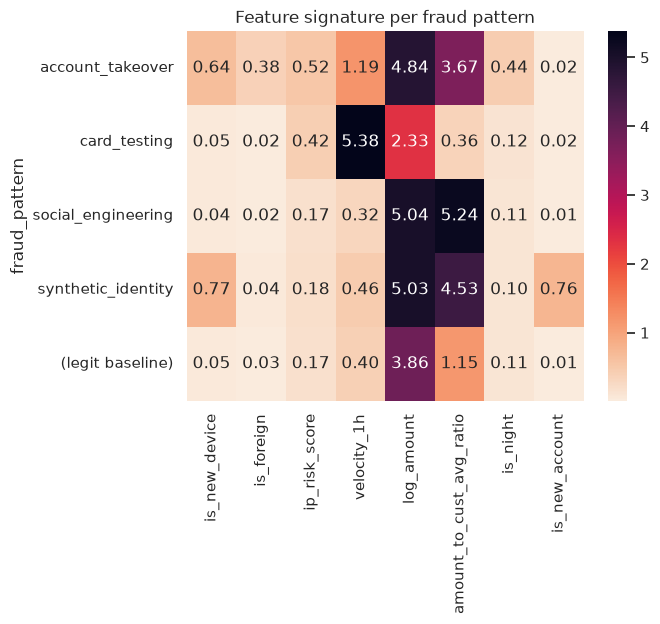

In [4]:
sig = fe[fe.is_fraud==1].groupby('fraud_pattern')[['is_new_device','is_foreign','ip_risk_score','velocity_1h','log_amount','amount_to_cust_avg_ratio','is_night','is_new_account']].mean()
legit = fe[fe.is_fraud==0][sig.columns].mean(); sig.loc['(legit baseline)'] = legit
sns.heatmap(sig.round(2), annot=True, cmap='rocket_r', fmt='.2f'); plt.title('Feature signature per fraud pattern')

In [5]:
missed = f[~f.pred]; print('missed frauds:', len(missed), '| value missed:', round(missed.amount.sum(), 1)); missed.fraud_pattern.value_counts()

missed frauds: 65 | value missed: 4948.0


fraud_pattern
account_takeover      25
social_engineering    23
card_testing          13
synthetic_identity     4
Name: count, dtype: int64

Social-engineering fraud (legitimate device and geography, customer authenticates with OTP) is the hardest class: its behavioural footprint resembles legitimate high-value transfers. This motivates behavioural/biometric signals and consumer education as complements to ML (see Chapter 6).